# Movie Genre Prediction with a Multi-Layer Perceptron

Issue #37 · Multi-label classification · Requirements 1–5 complete; final evaluation pending

## Data and goal

Source: `data/features/10_genre_features.csv` from the shared Week 5 Features folder. A movie may have multiple genre labels.

## 1. Select input features and genre targets

Use 15 numeric or Boolean features and original language as inputs. Predict 20 binary genre columns; a movie can have more than one genre. Exclude `id` and all genre labels from the inputs, plus post-release revenue and popularity. Long text and names need additional encoding, so this first model uses their prepared counts and indicators. Remove rows with no recorded genre rather than treating missing labels as confirmed negatives.

In [1]:
from pathlib import Path
import pandas as pd

# Find the CSV whether VS Code starts the notebook in the project root
# or in the notebook's own folder.
relative_path = Path("data/features/10_genre_features.csv")
csv_path = next(
    (folder / relative_path for folder in [Path.cwd(), *Path.cwd().parents]
     if (folder / relative_path).exists()),
    None,
)

if csv_path is None:
    raise FileNotFoundError(
        "Put 10_genre_features.csv in the project's data/features folder."
    )

movies = pd.read_csv(csv_path, low_memory=False)

# These 20 columns are the answers the model should predict.
genre_columns = [
    "Drama", "Crime", "Comedy", "Action", "Thriller",
    "Adventure", "Science Fiction", "Animation", "Family",
    "Romance", "Mystery", "Music", "Horror", "Fantasy",
    "Documentary", "War", "Western", "History", "Foreign", "TV Movie",
]

# Start with movie information that is usable around release time.
numeric_columns = [
    "release_year", "release_month", "log_budget", "runtime",
    "cast_size", "crew_size", "company_count", "country_count",
    "spoken_languages_count", "keyword_count", "title_word_count",
    "overview_word_count", "has_collection", "has_director",
    "title_differs_from_original",
]
categorical_columns = ["original_language"]
feature_columns = numeric_columns + categorical_columns

# Check that the CSV has the columns we expect and that genre labels are 0 or 1.
required_columns = feature_columns + genre_columns
missing_columns = sorted(set(required_columns) - set(movies.columns))
if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}")

if not movies[genre_columns].isin([0, 1]).all().all():
    raise ValueError("Some genre labels are not 0 or 1.")

# Rows with no recorded genre cannot teach the model a known genre.
has_recorded_genre = movies[genre_columns].sum(axis=1) > 0
X = movies.loc[has_recorded_genre, feature_columns].copy()
y = movies.loc[has_recorded_genre, genre_columns].astype(int).copy()

print(f"CSV: {csv_path}")
print(f"All movies: {len(movies):,}")
print(f"Movies with no recorded genre removed: {(~has_recorded_genre).sum():,}")
print(f"Movies available for modeling: {len(X):,}")
print(f"Input features ({len(feature_columns)}): {feature_columns}")
print(f"Genre targets ({len(genre_columns)}): {genre_columns}")
print("\nNumber of movies in each genre:")
print(y.sum().sort_values(ascending=False).to_string())

CSV: /home/tmcrtz/Documents/css-dsml-fall2027/data/features/10_genre_features.csv
All movies: 45,433
Movies with no recorded genre removed: 2,442
Movies available for modeling: 42,991
Input features (16): ['release_year', 'release_month', 'log_budget', 'runtime', 'cast_size', 'crew_size', 'company_count', 'country_count', 'spoken_languages_count', 'keyword_count', 'title_word_count', 'overview_word_count', 'has_collection', 'has_director', 'title_differs_from_original', 'original_language']
Genre targets (20): ['Drama', 'Crime', 'Comedy', 'Action', 'Thriller', 'Adventure', 'Science Fiction', 'Animation', 'Family', 'Romance', 'Mystery', 'Music', 'Horror', 'Fantasy', 'Documentary', 'War', 'Western', 'History', 'Foreign', 'TV Movie']

Number of movies in each genre:
Drama              20244
Comedy             13176
Thriller            7619
Romance             6730
Action              6592
Horror              4671
Crime               4304
Documentary         3930
Adventure           3490
S

## 2. Prepare numerical and categorical features

Treat zero log budgets as unknown, convert Boolean inputs to 0/1, fill missing numeric values with medians, scale numeric inputs, and one-hot encode original language. The preprocessing pipeline is defined here and fitted on training movies only after the split.

In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Keep the original X from Step 1 intact.
X_model = X.copy()

# The three true/false columns become 1.0/0.0 along with the other numbers.
X_model[numeric_columns] = X_model[numeric_columns].astype(float)

# In this dataset, budget 0 often stands for an unknown budget.
# Treat it as missing so the model does not assume every 0 means a real $0 budget.
zero_budget_count = X_model["log_budget"].eq(0).sum()
X_model["log_budget"] = X_model["log_budget"].mask(
    X_model["log_budget"].eq(0)
)

numeric_preprocessing = Pipeline([
    ("fill_missing", SimpleImputer(strategy="median", add_indicator=True)),
    ("scale", StandardScaler()),
])

categorical_preprocessing = Pipeline([
    ("fill_missing", SimpleImputer(strategy="most_frequent")),
    ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("numbers", numeric_preprocessing, numeric_columns),
    ("language", categorical_preprocessing, categorical_columns),
])

print(f"Zero budgets treated as missing: {zero_budget_count:,}")
print("\nColumns with the most missing values:")
print(X_model.isna().sum().sort_values(ascending=False).head(8).to_string())
print("\nPreprocessing pipeline created. It has not been fitted yet.")

Zero budgets treated as missing: 34,169

Columns with the most missing values:
log_budget           34169
runtime                182
release_month           29
release_year            29
original_language       10
cast_size                0
company_count            0
crew_size                0

Preprocessing pipeline created. It has not been fitted yet.


## 3. Create training, validation, and test splits

Use a fixed seed for an 80/10/10 split. Fit preprocessing on training movies; only transform validation and test movies. Reserve the test set for one final evaluation after selecting a model from validation results.

In [3]:
import numpy as np
from sklearn.model_selection import train_test_split

# First reserve 20% of movies for validation and testing.
X_train, X_holdout, y_train, y_holdout = train_test_split(
    X_model, y, test_size=0.20, random_state=42
)

# Divide that reserved group equally: 10% validation, 10% test.
X_validation, X_test, y_validation, y_test = train_test_split(
    X_holdout, y_holdout, test_size=0.50, random_state=42
)

# Confirm that each movie is in exactly one group.
assert set(X_train.index).isdisjoint(X_validation.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_validation.index).isdisjoint(X_test.index)

# Learn fill values, scaling, and language categories from training movies only.
X_train_ready = preprocessor.fit_transform(X_train)

# Apply those same learned rules to validation and test movies.
X_validation_ready = preprocessor.transform(X_validation)
X_test_ready = preprocessor.transform(X_test)

assert np.isfinite(X_train_ready).all()
assert np.isfinite(X_validation_ready).all()
assert np.isfinite(X_test_ready).all()

print(f"Training movies:   {len(X_train):,} ({len(X_train) / len(X_model):.0%})")
print(f"Validation movies: {len(X_validation):,} ({len(X_validation) / len(X_model):.0%})")
print(f"Test movies:       {len(X_test):,} ({len(X_test) / len(X_model):.0%})")
print(f"Total model inputs after preprocessing: {X_train_ready.shape[1]}")

# Check that even the less common genres appear in all three groups.
genre_counts = pd.DataFrame({
    "training": y_train.sum(),
    "validation": y_validation.sum(),
    "test": y_test.sum(),
})
print("\nFive least common genres across the splits:")
print(genre_counts.sum(axis=1).sort_values().head(5).index.to_list())
print(genre_counts.loc[genre_counts.sum(axis=1).sort_values().head(5).index])

Training movies:   34,392 (80%)
Validation movies: 4,299 (10%)
Test movies:       4,300 (10%)
Total model inputs after preprocessing: 101

Five least common genres across the splits:
['TV Movie', 'Western', 'War', 'History', 'Music']
          training  validation  test
TV Movie       614          73    79
Western        813         116   113
War           1049         132   141
History       1127         133   138
Music         1289         142   166


## 4. Train multiple MLP configurations

Train four MLPs using different hidden-layer layouts and learning rates. All use Adam, ReLU, batch size 256, and seed 42. Each reached the 80-iteration cap, so the convergence warnings must be considered when interpreting the scores.

In [4]:
import time
from sklearn.neural_network import MLPClassifier

# Each tuple describes the size of the hidden layers.
# For example, (64, 32) means two hidden layers with 64 and 32 neurons.
configurations = [
    {"name": "one_layer_32",  "layers": (32,),    "learning_rate": 0.001},
    {"name": "one_layer_64",  "layers": (64,),    "learning_rate": 0.001},
    {"name": "two_layers",   "layers": (64, 32), "learning_rate": 0.001},
    {"name": "slower_rate",  "layers": (64, 32), "learning_rate": 0.0003},
]

trained_models = {}
training_summary = []

for config in configurations:
    print(f"Training {config['name']}...")
    start_time = time.perf_counter()

    model = MLPClassifier(
        hidden_layer_sizes=config["layers"],
        learning_rate_init=config["learning_rate"],
        activation="relu",
        solver="adam",
        batch_size=256,
        max_iter=80,
        tol=0.001,
        n_iter_no_change=8,
        random_state=42,
    )

    model.fit(X_train_ready, y_train)

    trained_models[config["name"]] = model
    training_summary.append({
        "model": config["name"],
        "hidden_layers": str(config["layers"]),
        "learning_rate": config["learning_rate"],
        "iterations": model.n_iter_,
        "final_training_loss": model.loss_,
        "training_seconds": round(time.perf_counter() - start_time, 1),
    })

pd.DataFrame(training_summary)

Training one_layer_32...


/home/tmcrtz/Documents/css-dsml-fall2027/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (80) reached and the optimization hasn't converged yet.
  warnings.warn(


Training one_layer_64...


/home/tmcrtz/Documents/css-dsml-fall2027/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (80) reached and the optimization hasn't converged yet.
  warnings.warn(


Training two_layers...


/home/tmcrtz/Documents/css-dsml-fall2027/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (80) reached and the optimization hasn't converged yet.
  warnings.warn(


Training slower_rate...


/home/tmcrtz/Documents/css-dsml-fall2027/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (80) reached and the optimization hasn't converged yet.
  warnings.warn(


,model,hidden_layers,learning_rate,iterations,final_training_loss,training_seconds
0,one_layer_32,"(32,)",0.0010,80,5.022079,11.2
1,one_layer_64,"(64,)",0.0010,80,4.946679,15.5
2,two_layers,"(64, 32)",0.0010,80,4.849186,16.6
3,slower_rate,"(64, 32)",0.0003,80,4.967447,16.4


## 5. Compare validation precision, recall, and F1

Compare every configuration on the same validation movies. Micro scores combine all movie–genre decisions; macro F1 gives each genre equal weight. Count movies with no predicted genre to reveal low prediction coverage. Model selection and test evaluation follow in later requirements.

In [5]:
from sklearn.metrics import precision_score, recall_score, f1_score

validation_rows = []

for config in configurations:
    name = config["name"]
    model = trained_models[name]

    # Predict the 20 genre labels for validation movies only.
    predicted_genres = model.predict(X_validation_ready)
    assert predicted_genres.shape == y_validation.shape

    validation_rows.append({
        "model": name,
        "hidden_layers": str(config["layers"]),
        "learning_rate": config["learning_rate"],
        "micro_precision": precision_score(
            y_validation, predicted_genres, average="micro", zero_division=0
        ),
        "micro_recall": recall_score(
            y_validation, predicted_genres, average="micro", zero_division=0
        ),
        "micro_f1": f1_score(
            y_validation, predicted_genres, average="micro", zero_division=0
        ),
        "macro_f1": f1_score(
            y_validation, predicted_genres, average="macro", zero_division=0
        ),
        "movies_with_no_predicted_genre": (
            predicted_genres.sum(axis=1) == 0
        ).sum(),
    })

validation_results = (
    pd.DataFrame(validation_rows)
    .sort_values("micro_f1", ascending=False)
    .reset_index(drop=True)
)

print(validation_results.to_string(
    index=False,
    formatters={"learning_rate": lambda value: f"{value:.4f}"},
    float_format=lambda value: f"{value:.3f}"
))

       model hidden_layers learning_rate  micro_precision  micro_recall  micro_f1  macro_f1  movies_with_no_predicted_genre
  two_layers      (64, 32)        0.0010            0.647         0.229     0.338     0.148                            1492
one_layer_32         (32,)        0.0010            0.641         0.218     0.326     0.124                            1502
 slower_rate      (64, 32)        0.0003            0.658         0.215     0.324     0.130                            1598
one_layer_64         (64,)        0.0010            0.645         0.215     0.323     0.135                            1591


## 6–12. Final selection, test evaluation, charts, inference, and discussion



In [6]:
for config in configurations:
    name = config["name"]
    model = trained_models[name]
    print(name, " Validation set score:", model.score(X_validation_ready, y_validation), end=" ")
    print()

one_layer_32  Validation set score: 0.13421725982786695 
one_layer_64  Validation set score: 0.1335194231216562 
two_layers  Validation set score: 0.1337520353570598 
slower_rate  Validation set score: 0.13421725982786695 


In [7]:
from sklearn.metrics import classification_report, hamming_loss, jaccard_score

y_pred = trained_models["two_layers"].predict(X_test_ready)

print(classification_report(y_test, y_pred, target_names=genre_columns))

print("Micro F1:",
      f1_score(y_test, y_pred, average="micro"))

print("Macro F1:",
      f1_score(y_test, y_pred, average="macro"))

print("Micro precision:",
      precision_score(y_test, y_pred, average="micro"))

print("Micro recall:",
      recall_score(y_test, y_pred, average="micro"))

print("Hamming loss:",
      hamming_loss(y_test, y_pred))

print("Macro Jaccard:",
      jaccard_score(y_test, y_pred, average="macro"))

                 precision    recall  f1-score   support

          Drama       0.67      0.66      0.67      2029
          Crime       0.33      0.00      0.01       407
         Comedy       0.56      0.16      0.25      1344
         Action       0.64      0.15      0.24       643
       Thriller       0.58      0.08      0.14       750
      Adventure       0.68      0.04      0.07       353
Science Fiction       0.00      0.00      0.00       334
      Animation       0.77      0.39      0.52       187
         Family       0.75      0.09      0.16       270
        Romance       0.53      0.02      0.05       652
        Mystery       0.50      0.02      0.03       243
          Music       0.00      0.00      0.00       166
         Horror       0.53      0.11      0.18       470
        Fantasy       0.25      0.00      0.01       237
    Documentary       0.73      0.48      0.58       426
            War       0.50      0.01      0.03       141
        Western       0.00    

/home/tmcrtz/Documents/css-dsml-fall2027/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/tmcrtz/Documents/css-dsml-fall2027/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


Macro F1: 0.15079280720888835
Micro precision: 0.6554517133956387
Micro recall: 0.23012140435305697
Hamming loss: 0.09470930232558139
Macro Jaccard: 0.09710021119521252


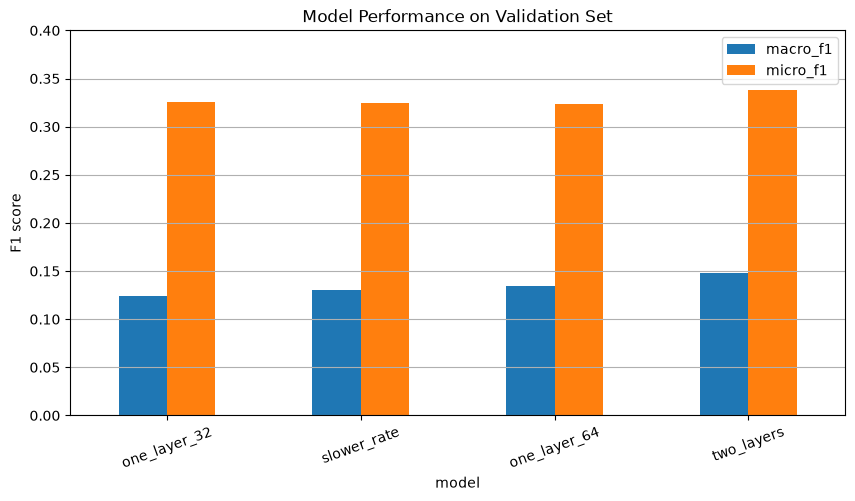

In [9]:
import matplotlib.pyplot as plt

plot_df = validation_results.sort_values("macro_f1")

plot_df.plot(
    x="model",
    y=["macro_f1", "micro_f1"],
    kind="bar",
    figsize=(10, 5)
)

plt.ylabel("F1 score")
plt.title("Model Performance on Validation Set")
plt.ylim(0, 0.4)
plt.xticks(rotation=20)
plt.grid(axis="y")
plt.show()

In [33]:
test_movie = X_test_ready[0].reshape(1,-1)

test_prediction = trained_models["two_layers"].predict(test_movie)[0]

print("Predicted genres: ", test_prediction)
print("Actual genres:\n", y_test.iloc[0])

Predicted genres:  [1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Actual genres:
 Drama              1
Crime              0
Comedy             1
Action             0
Thriller           0
Adventure          0
Science Fiction    0
Animation          0
Family             0
Romance            0
Mystery            0
Music              0
Horror             0
Fantasy            0
Documentary        0
War                0
Western            0
History            0
Foreign            0
TV Movie           0
Name: 27591, dtype: int64
